# K-Nearest Neighbors for Clinical AI

## CAIR Workshop Series - Part 4

**Learning Objectives:**
- Understand how KNN makes predictions using similarity
- Learn distance metrics and their impact on clinical applications
- Visualize decision boundaries for mobility phenotype classification
- Explore the curse of dimensionality with wearable sensor data
- Compare KNN with decision trees for clinical scenarios

**Duration:** ~25 minutes

---

K-Nearest Neighbors (KNN) is one of the simplest yet most intuitive machine learning algorithms. It makes predictions by asking: **"What happened to patients similar to this one?"**

In this notebook, we'll apply KNN to **mobility phenotype classification** - identifying whether an inpatient is functionally independent, requires assistance, or is bed-bound, based on continuous wearable-accelerometer data.

> **A note on the data.** Every patient record in this notebook is simulated from
> published activity-monitoring ranges. No real or identifiable patient data is used.


In [1]:
# Essential imports for clinical KNN analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings('ignore')

# Set style for professional clinical presentations
plt.style.use('default')
sns.set_palette("husl")
np.random.seed(42)

print("🩺 Clinical K-Nearest Neighbors: Ready for Mobility Phenotype Analysis")
print("   This notebook demonstrates similarity-based AI for clinical operations")

🩺 Clinical K-Nearest Neighbors: Ready for Mobility Phenotype Analysis
   This notebook demonstrates similarity-based AI for clinical operations


## 1. Mobility Phenotype Dataset

We'll create a realistic dataset capturing 24 hours of movement captured by a wrist- or waist-worn accelerometer:

**Movement Features:**
- Mean cadence (steps per minute while walking)
- Cadence variance (step-to-step irregularity)
- Posture changes per hour (lie/sit/stand transitions)
- Time out of the room (%)
- Gait radius (metres from the bed, from indoor localization)
- Active minutes per day

**Mobility Phenotypes:**
- **Independent**: Brisk steady cadence, frequent posture changes, walks well beyond the room
- **Assisted**: Slower and more irregular cadence, fewer transitions, short supervised walks
- **Bed-bound**: Minimal ambulation, few repositioning events, essentially confined to the bed space

Mobility phenotype is one of the strongest predictors of falls, delirium, deconditioning
and discharge destination, which makes it worth classifying automatically.


In [2]:
def generate_mobility_phenotype_data(n_samples=600):
    """
    Generate synthetic but realistic patient mobility data from wearable sensors.
    Based on patterns reported in inpatient accelerometry studies.

    The values are simulated. No real or identifiable patient data is used.
    """
    np.random.seed(42)

    # Number of samples per class
    n_per_class = n_samples // 3

    # INDEPENDENT: brisk steady cadence, frequent transitions, walks off the ward
    indep_cadence = np.random.normal(96, 14, n_per_class)       # Brisk
    indep_cadence_var = np.random.gamma(1.5, 0.6, n_per_class)  # Steady, regular gait
    indep_posture = np.random.gamma(5, 2, n_per_class)          # Many transitions
    indep_out_of_room = np.random.beta(3, 2, n_per_class) * 100 # Often off the ward
    indep_radius = np.random.gamma(7, 6, n_per_class)           # Walks a long way
    indep_active = np.random.normal(210, 70, n_per_class)       # Highly active

    # ASSISTED: slower, more irregular gait, short supervised walks
    assist_cadence = np.random.normal(76, 15, n_per_class)      # Slower
    assist_cadence_var = np.random.gamma(3, 0.9, n_per_class)   # Irregular gait
    assist_posture = np.random.gamma(4, 1.3, n_per_class)       # Fewer transitions
    assist_out_of_room = np.random.beta(1.5, 4, n_per_class) * 100
    assist_radius = np.random.gamma(3, 6, n_per_class)          # Short walks
    assist_active = np.random.gamma(5, 20, n_per_class)         # Modest activity

    # BED-BOUND: minimal ambulation, repositioning only, confined to the bed space
    bed_cadence = np.random.normal(52, 17, n_per_class)         # Transfers only
    bed_cadence_var = np.random.gamma(3.5, 1.0, n_per_class)    # Erratic, very few steps
    bed_posture = np.random.gamma(2, 1.1, n_per_class)          # Repositioning only
    bed_out_of_room = np.random.beta(1, 15, n_per_class) * 100  # Rarely leaves the room
    bed_radius = np.random.exponential(4, n_per_class)          # Bed space only
    bed_active = np.random.gamma(2.5, 12, n_per_class)          # Very low activity

    # Combine all data
    data = pd.DataFrame({
        'mean_cadence': np.concatenate([indep_cadence, assist_cadence, bed_cadence]),
        'cadence_variance': np.concatenate([indep_cadence_var, assist_cadence_var, bed_cadence_var]),
        'posture_changes_hr': np.concatenate([indep_posture, assist_posture, bed_posture]),
        'pct_time_out_of_room': np.concatenate([indep_out_of_room, assist_out_of_room, bed_out_of_room]),
        'gait_radius_m': np.concatenate([indep_radius, assist_radius, bed_radius]),
        'active_minutes': np.concatenate([indep_active, assist_active, bed_active]),
        'phenotype': ['Independent'] * n_per_class + ['Assisted'] * n_per_class + ['Bed-bound'] * n_per_class
    })

    # Ensure physiologically realistic bounds
    data['mean_cadence'] = data['mean_cadence'].clip(0, 140)
    data['cadence_variance'] = data['cadence_variance'].clip(0, 8)
    data['posture_changes_hr'] = data['posture_changes_hr'].clip(0, 30)
    data['pct_time_out_of_room'] = data['pct_time_out_of_room'].clip(0, 100)
    data['gait_radius_m'] = data['gait_radius_m'].clip(0, 200)
    data['active_minutes'] = data['active_minutes'].clip(0, 600)

    return data

# Generate our mobility phenotype dataset
patient_data = generate_mobility_phenotype_data(600)

print("🩺 Mobility Phenotype Dataset Generated (simulated, no real patient data)")
print(f"   Total samples: {len(patient_data)}")
print(f"   Phenotypes: {patient_data['phenotype'].value_counts().to_dict()}")

# Display first few examples
print("\n📊 Sample Data:")
patient_data.head(10)


🩺 Mobility Phenotype Dataset Generated (simulated, no real patient data)
   Total samples: 600
   Phenotypes: {'Independent': 200, 'Assisted': 200, 'Bed-bound': 200}

📊 Sample Data:


,mean_cadence,cadence_variance,posture_changes_hr,pct_time_out_of_room,gait_radius_m,active_minutes,phenotype
0,102.953998,0.958417,2.633028,55.335055,43.570779,305.879614,Independent
1,94.064300,1.129954,4.035348,79.965791,28.775521,237.469118,Independent
2,105.067640,0.132967,9.402864,26.490886,49.969794,174.372546,Independent
3,117.322418,0.251153,13.744290,57.048425,75.052886,208.209798,Independent
4,92.721853,1.089655,9.752586,48.952532,45.684156,86.164687,Independent
5,92.722083,1.518151,10.065402,48.719252,37.491974,161.370081,Independent
6,118.108979,1.212698,12.013528,84.828538,63.834818,181.350229,Independent
7,106.744086,0.309107,11.711608,45.587152,32.765480,173.313812,Independent
8,89.427359,0.557467,15.826162,61.763702,57.433718,220.664841,Independent
9,103.595841,3.526737,7.381945,64.635843,31.866193,152.430605,Independent


## 2. Visualizing Mobility Patterns

Let's visualize how the three mobility phenotypes cluster in the feature space. KNN will use these patterns to classify new patients.


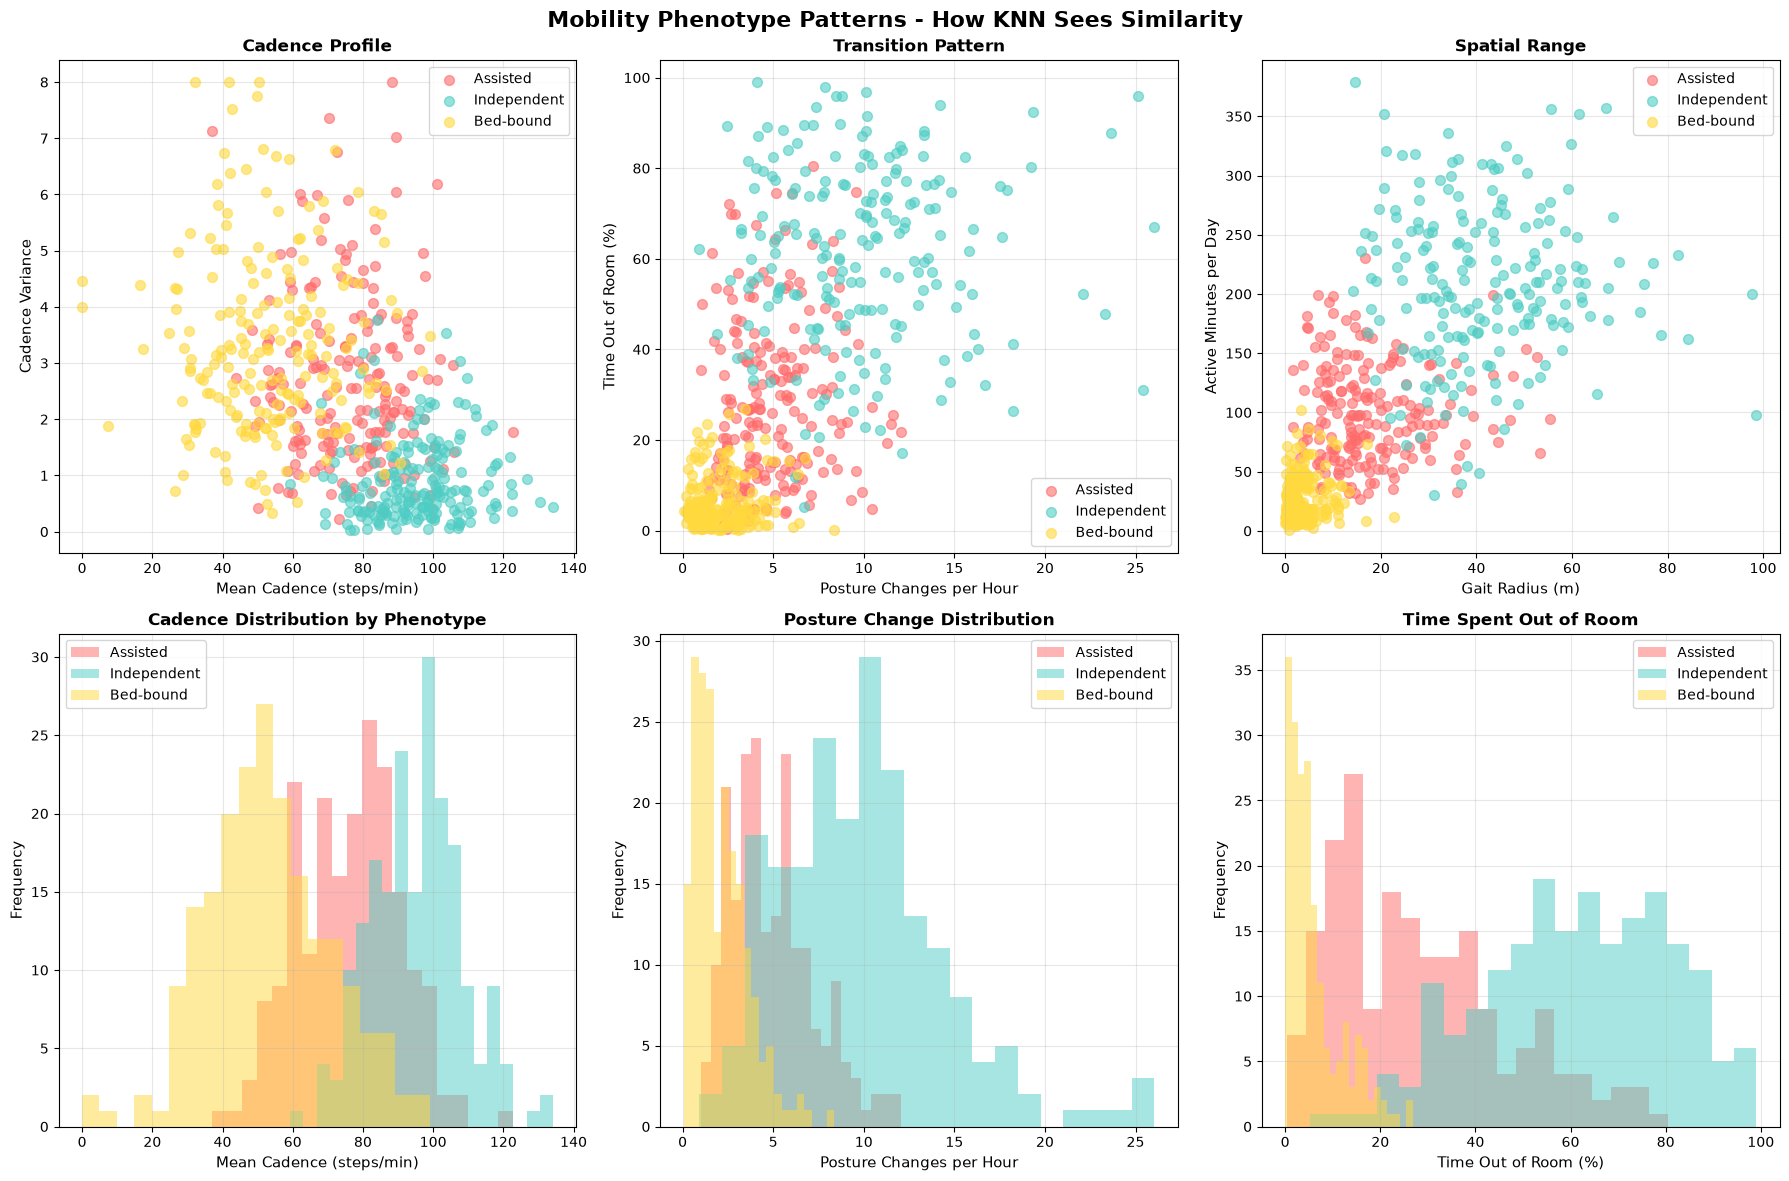


🔍 Pattern Observations:
   • Independent patients: brisk, steady, wide-ranging (teal clusters)
   • Assisted patients: slower, irregular gait, short supervised walks (red clusters)
   • Bed-bound patients: minimal ambulation, confined to the bed space (yellow clusters)
   • KNN will find 'neighbors' in this multi-dimensional space


In [3]:
# Create comprehensive visualization of patient patterns
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Mobility Phenotype Patterns - How KNN Sees Similarity', fontsize=16, fontweight='bold')

# Define colors for phenotypes
colors = {'Assisted': '#FF6B6B', 'Independent': '#4ECDC4', 'Bed-bound': '#FFD93D'}

# Plot 1: Cadence vs Cadence Variance
ax = axes[0, 0]
for phenotype in ['Assisted', 'Independent', 'Bed-bound']:
    mask = patient_data['phenotype'] == phenotype
    ax.scatter(patient_data[mask]['mean_cadence'], 
               patient_data[mask]['cadence_variance'],
               c=colors[phenotype], label=phenotype, alpha=0.6, s=50)
ax.set_xlabel('Mean Cadence (steps/min)', fontsize=11)
ax.set_ylabel('Cadence Variance', fontsize=11)
ax.set_title('Cadence Profile', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Posture Changes vs Time Out of Room
ax = axes[0, 1]
for phenotype in ['Assisted', 'Independent', 'Bed-bound']:
    mask = patient_data['phenotype'] == phenotype
    ax.scatter(patient_data[mask]['posture_changes_hr'], 
               patient_data[mask]['pct_time_out_of_room'],
               c=colors[phenotype], label=phenotype, alpha=0.6, s=50)
ax.set_xlabel('Posture Changes per Hour', fontsize=11)
ax.set_ylabel('Time Out of Room (%)', fontsize=11)
ax.set_title('Transition Pattern', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Gait Radius vs Active Minutes
ax = axes[0, 2]
for phenotype in ['Assisted', 'Independent', 'Bed-bound']:
    mask = patient_data['phenotype'] == phenotype
    ax.scatter(patient_data[mask]['gait_radius_m'], 
               patient_data[mask]['active_minutes'],
               c=colors[phenotype], label=phenotype, alpha=0.6, s=50)
ax.set_xlabel('Gait Radius (m)', fontsize=11)
ax.set_ylabel('Active Minutes per Day', fontsize=11)
ax.set_title('Spatial Range', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Cadence Distribution
ax = axes[1, 0]
for phenotype in ['Assisted', 'Independent', 'Bed-bound']:
    mask = patient_data['phenotype'] == phenotype
    ax.hist(patient_data[mask]['mean_cadence'], bins=20, alpha=0.5, 
            label=phenotype, color=colors[phenotype])
ax.set_xlabel('Mean Cadence (steps/min)', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('Cadence Distribution by Phenotype', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 5: Posture Change Distribution
ax = axes[1, 1]
for phenotype in ['Assisted', 'Independent', 'Bed-bound']:
    mask = patient_data['phenotype'] == phenotype
    ax.hist(patient_data[mask]['posture_changes_hr'], bins=20, alpha=0.5,
            label=phenotype, color=colors[phenotype])
ax.set_xlabel('Posture Changes per Hour', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('Posture Change Distribution', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 6: Time Spent Out of Room
ax = axes[1, 2]
for phenotype in ['Assisted', 'Independent', 'Bed-bound']:
    mask = patient_data['phenotype'] == phenotype
    ax.hist(patient_data[mask]['pct_time_out_of_room'], bins=20, alpha=0.5,
            label=phenotype, color=colors[phenotype])
ax.set_xlabel('Time Out of Room (%)', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('Time Spent Out of Room', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n🔍 Pattern Observations:")
print("   • Independent patients: brisk, steady, wide-ranging (teal clusters)")
print("   • Assisted patients: slower, irregular gait, short supervised walks (red clusters)")
print("   • Bed-bound patients: minimal ambulation, confined to the bed space (yellow clusters)")
print("   • KNN will find 'neighbors' in this multi-dimensional space")

## 3. How KNN Works: The Core Algorithm

KNN makes predictions in three simple steps:

1. **Calculate distance** from the new patient to all known patients
2. **Find the K nearest neighbors** (patients with smallest distances)
3. **Vote**: Predict the most common phenotype among the K neighbors

Let's build our first KNN classifier and see it in action!


In [4]:
# Prepare data for KNN
X = patient_data[['mean_cadence', 'cadence_variance', 'posture_changes_hr',
                 'pct_time_out_of_room', 'gait_radius_m', 'active_minutes']]
y = patient_data['phenotype']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# IMPORTANT: KNN requires feature scaling!
# Without scaling, features with large values dominate distance calculations
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("⚙️  Feature Scaling Example:")
print("\nOriginal features (first sample):")
print(X_train.iloc[0])
print("\nScaled features (first sample):")
print(pd.Series(X_train_scaled[0], index=X.columns))
print("\n💡 Scaling ensures all features contribute equally to distance!")

# Train KNN with K=5
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Make predictions
y_pred = knn.predict(X_test_scaled)

# Evaluate
train_accuracy = knn.score(X_train_scaled, y_train)
test_accuracy = knn.score(X_test_scaled, y_test)

print("\n🎯 KNN Classifier Results (K=5)")
print("=" * 50)
print(f"Training Accuracy: {train_accuracy:.3f}")
print(f"Testing Accuracy:  {test_accuracy:.3f}")
print(f"\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

⚙️  Feature Scaling Example:

Original features (first sample):
mean_cadence            104.215999
cadence_variance          1.548258
posture_changes_hr       16.014901
pct_time_out_of_room     66.618398
gait_radius_m            18.058085
active_minutes          249.038374
Name: 124, dtype: float64

Scaled features (first sample):
mean_cadence            1.286525
cadence_variance       -0.447753
posture_changes_hr      2.405827
pct_time_out_of_room    1.283865
gait_radius_m          -0.156907
active_minutes          1.647973
dtype: float64

💡 Scaling ensures all features contribute equally to distance!

🎯 KNN Classifier Results (K=5)
Training Accuracy: 0.971
Testing Accuracy:  0.950

Detailed Classification Report:
              precision    recall  f1-score   support

    Assisted       0.93      0.93      0.93        40
   Bed-bound       0.97      0.97      0.97        40
 Independent       0.95      0.95      0.95        40

    accuracy                           0.95       120
   

## 4. Understanding KNN: Progressive Visualizations

To truly understand how KNN makes predictions, let's watch the algorithm work step-by-step. These interactive visualizations show:

1. **Step-by-Step Neighbor Discovery**: Watch as KNN finds neighbors one at a time and builds up its vote
2. **K-Sensitivity Explorer**: See how changing K affects the prediction for the same query point

These visualizations reveal the core intuition: **KNN simply finds similar examples and lets them vote.**

🩺 Interactive KNN Explorer
• Adjust K with the slider
• Click anywhere to place a patient and see classification
• Click again to try a different location


HTML(value='<b>👆 Click anywhere on the plot to classify a patient</b>')

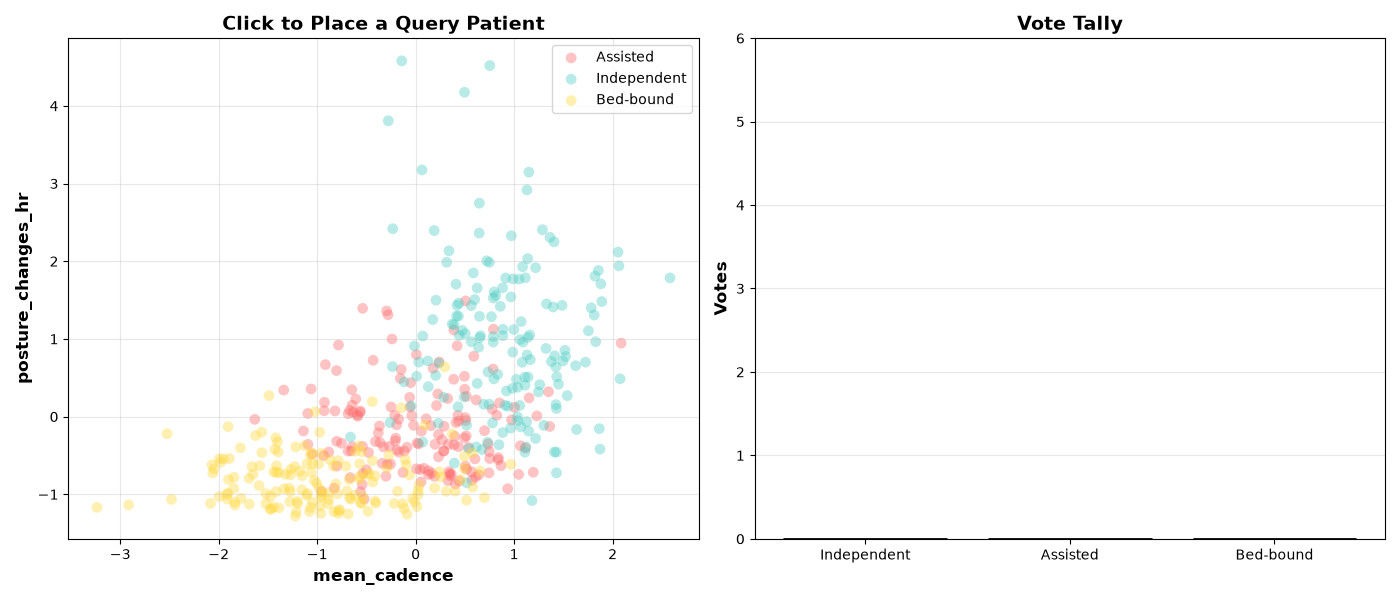

In [5]:
%matplotlib widget
import matplotlib.patheffects as mpl_patheffects
import ipywidgets as widgets
from IPython.display import display

class InteractiveKNNExplorer:
    """
    Interactive KNN: Click anywhere to place a patient and instantly see the K nearest neighbors.
    """
    def __init__(self, X_train_data, y_train_data, feature_names=('mean_cadence', 'posture_changes_hr')):
        self.X_train_data = X_train_data
        self.y_train_data = y_train_data
        self.feature_names = feature_names
        
        # Get 2D projection for visualization
        self.feat_idx = [list(X.columns).index(feature_names[0]), 
                         list(X.columns).index(feature_names[1])]
        self.X_2d = X_train_data[:, self.feat_idx]
        
        # Colors
        self.colors = {'Assisted': '#FF6B6B', 'Independent': '#4ECDC4', 'Bed-bound': '#FFD93D'}
        
        # Create K slider
        self.k_slider = widgets.IntSlider(value=5, min=1, max=15, step=1, 
                                          description='K neighbors:',
                                          style={'description_width': '100px'},
                                          layout=widgets.Layout(width='300px'))
        self.k_slider.observe(self.on_k_change, names='value')
        
        self.status_label = widgets.HTML(value='<b>👆 Click anywhere on the plot to classify a patient</b>')
        
        # Current query point
        self.query_point = None
        
        # Create figure
        self.fig, (self.ax1, self.ax2) = plt.subplots(1, 2, figsize=(14, 6))
        self.fig.canvas.header_visible = False
        
        # Connect click event
        self.fig.canvas.mpl_connect('button_press_event', self.on_click)
        
        # Store axis limits
        self.draw_base_plot()
        self.xlim = self.ax1.get_xlim()
        self.ylim = self.ax1.get_ylim()
        self.draw_empty_votes()
        
        # Display widgets
        display(widgets.HBox([self.k_slider]))
        display(self.status_label)
        plt.tight_layout()
        plt.show()
    
    def draw_base_plot(self):
        """Draw the training data points."""
        self.ax1.clear()
        
        for phenotype in ['Assisted', 'Independent', 'Bed-bound']:
            mask = self.y_train_data == phenotype
            self.ax1.scatter(self.X_2d[mask, 0], self.X_2d[mask, 1], 
                           c=self.colors[phenotype], label=phenotype, 
                           alpha=0.4, s=60, edgecolors='none')
        
        self.ax1.set_xlabel(self.feature_names[0], fontsize=12, fontweight='bold')
        self.ax1.set_ylabel(self.feature_names[1], fontsize=12, fontweight='bold')
        self.ax1.set_title('Click to Place a Query Patient', fontsize=14, fontweight='bold')
        self.ax1.legend(loc='upper right', fontsize=10)
        self.ax1.grid(True, alpha=0.3)
    
    def draw_empty_votes(self):
        """Draw empty vote tally."""
        self.ax2.clear()
        self.ax2.bar(['Independent', 'Assisted', 'Bed-bound'], [0, 0, 0], 
                     color=['#4ECDC4', '#FF6B6B', '#FFD93D'],
                     edgecolor='black', linewidth=2)
        self.ax2.set_ylabel('Votes', fontsize=12, fontweight='bold')
        self.ax2.set_ylim(0, self.k_slider.value + 1)
        self.ax2.set_title('Vote Tally', fontsize=14, fontweight='bold')
        self.ax2.grid(True, alpha=0.3, axis='y')
    
    def on_k_change(self, change):
        """Re-run KNN when K changes (if we have a query point)."""
        if self.query_point is not None:
            self.run_knn()
    
    def on_click(self, event):
        """Handle click events on the plot."""
        if event.inaxes != self.ax1:
            return
        if event.xdata is None or event.ydata is None:
            return
        
        # Store query point and run KNN
        self.query_point = np.array([event.xdata, event.ydata])
        self.run_knn()
    
    def run_knn(self):
        """Calculate and display KNN result immediately."""
        k = self.k_slider.value
        
        # Reset and redraw base plot
        self.draw_base_plot()
        self.ax1.set_xlim(self.xlim)
        self.ax1.set_ylim(self.ylim)
        
        # Draw query point
        self.ax1.scatter(self.query_point[0], self.query_point[1], 
                        c='black', s=400, marker='*', zorder=10,
                        edgecolors='white', linewidths=2, label='Query')
        self.ax1.legend(loc='upper right', fontsize=10)
        
        # Calculate distances and find K nearest
        distances = np.sqrt(np.sum((self.X_2d - self.query_point) ** 2, axis=1))
        sorted_indices = np.argsort(distances)
        
        # Count votes and draw neighbors
        votes = {'Independent': 0, 'Assisted': 0, 'Bed-bound': 0}
        
        for i in range(k):
            idx = sorted_indices[i]
            neighbor_phenotype = self.y_train_data.iloc[idx]
            neighbor_pos = self.X_2d[idx]
            dist = distances[idx]
            votes[neighbor_phenotype] += 1
            
            # Draw line to neighbor
            self.ax1.plot([self.query_point[0], neighbor_pos[0]], 
                         [self.query_point[1], neighbor_pos[1]],
                         color=self.colors[neighbor_phenotype], linewidth=2, 
                         alpha=0.7, zorder=5)
            
            # Highlight neighbor
            self.ax1.scatter(neighbor_pos[0], neighbor_pos[1], 
                            c=self.colors[neighbor_phenotype], s=200,
                            edgecolors='black', linewidths=2, zorder=6)
            
            # Add neighbor number
            self.ax1.annotate(str(i+1), (neighbor_pos[0], neighbor_pos[1]), 
                             fontsize=8, ha='center', va='center', fontweight='bold',
                             color='white', zorder=7,
                             path_effects=[mpl_patheffects.withStroke(linewidth=3, foreground='black')])
        
        # Draw circle around K neighbors
        furthest_dist = distances[sorted_indices[k-1]]
        circle = plt.Circle((self.query_point[0], self.query_point[1]), 
                            furthest_dist, fill=False, color='gray', 
                            linestyle='--', linewidth=2, alpha=0.6)
        self.ax1.add_patch(circle)
        
        # Determine prediction
        prediction = max(votes, key=votes.get)
        confidence = votes[prediction] / k * 100
        
        self.ax1.set_title(f'Prediction: {prediction} ({confidence:.0f}% confidence)', 
                          fontsize=14, fontweight='bold', color='darkgreen')
        
        # Update vote tally
        self.ax2.clear()
        vote_counts = [votes['Independent'], votes['Assisted'], votes['Bed-bound']]
        bars = self.ax2.bar(['Independent', 'Assisted', 'Bed-bound'], vote_counts,
                           color=['#4ECDC4', '#FF6B6B', '#FFD93D'],
                           edgecolor='black', linewidth=2)
        
        # Add count labels
        for bar, count in zip(bars, vote_counts):
            if count > 0:
                self.ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
                             str(count), ha='center', va='bottom', 
                             fontsize=14, fontweight='bold')
        
        self.ax2.set_ylabel('Votes', fontsize=12, fontweight='bold')
        self.ax2.set_ylim(0, k + 1)
        self.ax2.axhline(y=k/2, color='red', linestyle='--', linewidth=1, alpha=0.5)
        self.ax2.set_title(f'{prediction}: {votes[prediction]}/{k} votes', 
                          fontsize=14, fontweight='bold', color='darkgreen')
        self.ax2.grid(True, alpha=0.3, axis='y')
        
        self.status_label.value = f'<b>🎯 {prediction} ({confidence:.0f}%) | Adjust K or click again to try another location</b>'
        
        self.fig.canvas.draw_idle()

# Launch the interactive explorer
print("🩺 Interactive KNN Explorer")
print("=" * 50)
print("• Adjust K with the slider")
print("• Click anywhere to place a patient and see classification")
print("• Click again to try a different location")
print("=" * 50)

explorer = InteractiveKNNExplorer(X_train_scaled, y_train)

In [6]:
# def visualize_k_sensitivity(X_train_data, y_train_data, query_point, max_k=20,
#                              feature_names=('mean_cadence', 'posture_changes_hr')):
#     """
#     Show how the prediction changes as K increases from 1 to max_k.
#     Reveals the stability (or instability) of the prediction.
#     """
#     # Use 2 features for visualization
#     feat_idx = [list(X.columns).index(feature_names[0]), 
#                 list(X.columns).index(feature_names[1])]
#     X_2d = X_train_data[:, feat_idx]
#     query_scaled = scaler.transform([query_point])
#     query_2d = query_scaled[0, feat_idx]
    
#     # Calculate all distances and sort
#     distances = np.sqrt(np.sum((X_2d - query_2d) ** 2, axis=1))
#     sorted_indices = np.argsort(distances)
    
#     # Colors for phenotypes
#     colors = {'Assisted': '#FF6B6B', 'Independent': '#4ECDC4', 'Bed-bound': '#FFD93D'}
#     color_list = ['#4ECDC4', '#FF6B6B', '#FFD93D']  # Independent, Assisted, Bed-bound order
    
#     print("=" * 70)
#     print("📊 K-SENSITIVITY: How Does Changing K Affect the Prediction?")
#     print("=" * 70)
#     print(f"\n📍 Query patient: Cadence={query_point[0]:.1f} steps/min, Posture changes={query_point[2]:.1f}/hr")
#     print(f"   Testing K from 1 to {max_k}...\n")
    
#     # Track predictions and confidences for each K
#     k_values = list(range(1, max_k + 1))
#     predictions = []
#     confidences = {'Independent': [], 'Assisted': [], 'Bed-bound': []}
    
#     for k in k_values:
#         votes = {'Independent': 0, 'Assisted': 0, 'Bed-bound': 0}
#         for i in range(k):
#             neighbor_phenotype = y_train_data.iloc[sorted_indices[i]]
#             votes[neighbor_phenotype] += 1
        
#         prediction = max(votes, key=votes.get)
#         predictions.append(prediction)
        
#         for phenotype in ['Independent', 'Assisted', 'Bed-bound']:
#             confidences[phenotype].append(votes[phenotype] / k * 100)
    
#     # Create visualization
#     fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
#     # Plot 1: Confidence curves over K
#     ax1 = axes[0, 0]
#     ax1.plot(k_values, confidences['Independent'], label='Independent', color='#4ECDC4', linewidth=3, marker='o', markersize=4)
#     ax1.plot(k_values, confidences['Assisted'], label='Assisted', color='#FF6B6B', linewidth=3, marker='s', markersize=4)
#     ax1.plot(k_values, confidences['Bed-bound'], label='Bed-bound', color='#FFD93D', linewidth=3, marker='^', markersize=4)
#     ax1.axhline(y=50, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='Majority (50%)')
#     ax1.set_xlabel('K (Number of Neighbors)', fontsize=12, fontweight='bold')
#     ax1.set_ylabel('Vote Percentage (%)', fontsize=12, fontweight='bold')
#     ax1.set_title('Confidence by Phenotype as K Changes', fontsize=14, fontweight='bold')
#     ax1.legend(loc='upper right', fontsize=10)
#     ax1.grid(True, alpha=0.3)
#     ax1.set_xlim(1, max_k)
#     ax1.set_ylim(0, 105)
    
#     # Plot 2: Prediction stability (colored bars showing prediction at each K)
#     ax2 = axes[0, 1]
#     pred_colors = [colors[p] for p in predictions]
#     bars = ax2.bar(k_values, [100]*len(k_values), color=pred_colors, edgecolor='black', linewidth=0.5)
#     ax2.set_xlabel('K (Number of Neighbors)', fontsize=12, fontweight='bold')
#     ax2.set_ylabel('', fontsize=12)
#     ax2.set_title('Prediction at Each K Value\n(Color = Predicted Class)', fontsize=14, fontweight='bold')
#     ax2.set_xlim(0.5, max_k + 0.5)
#     ax2.set_ylim(0, 100)
#     ax2.set_yticks([])
    
#     # Add legend for colors
#     from matplotlib.patches import Patch
#     legend_elements = [Patch(facecolor='#4ECDC4', edgecolor='black', label='Independent'),
#                       Patch(facecolor='#FF6B6B', edgecolor='black', label='Assisted'),
#                       Patch(facecolor='#FFD93D', edgecolor='black', label='Bed-bound')]
#     ax2.legend(handles=legend_elements, loc='upper right', fontsize=10)
    
#     # Highlight prediction changes
#     for i in range(1, len(predictions)):
#         if predictions[i] != predictions[i-1]:
#             ax2.axvline(x=i+0.5, color='red', linestyle='-', linewidth=2, alpha=0.7)
#             ax2.text(i+0.5, 50, '⚠️', fontsize=12, ha='center', va='center')
    
#     # Plot 3: Scatter plot with all K neighbors highlighted
#     ax3 = axes[1, 0]
#     for phenotype in ['Assisted', 'Independent', 'Bed-bound']:
#         mask = y_train_data == phenotype
#         ax3.scatter(X_2d[mask, 0], X_2d[mask, 1], 
#                    c=colors[phenotype], label=phenotype, 
#                    alpha=0.3, s=50, edgecolors='none')
    
#     # Highlight all max_k neighbors
#     for i in range(max_k):
#         idx = sorted_indices[i]
#         neighbor_phenotype = y_train_data.iloc[idx]
#         neighbor_pos = X_2d[idx]
#         ax3.scatter(neighbor_pos[0], neighbor_pos[1], c=colors[neighbor_phenotype], 
#                    s=150, edgecolors='black', linewidths=1.5, zorder=5, alpha=0.8)
#         ax3.annotate(str(i+1), (neighbor_pos[0], neighbor_pos[1]), fontsize=7, 
#                     ha='center', va='center', fontweight='bold', color='white',
#                     path_effects=[plt.matplotlib.patheffects.withStroke(linewidth=2, foreground='black')])
    
#     # Draw circle around K=max_k neighbors
#     furthest_dist = distances[sorted_indices[max_k-1]]
#     circle = plt.Circle((query_2d[0], query_2d[1]), furthest_dist, 
#                         fill=False, color='gray', linestyle='--', linewidth=2, alpha=0.5)
#     ax3.add_patch(circle)
    
#     # Plot query point
#     ax3.scatter(query_2d[0], query_2d[1], c='black', s=300, marker='*', 
#                zorder=10, label='Query', edgecolors='white', linewidths=2)
    
#     ax3.set_xlabel(feature_names[0], fontsize=12, fontweight='bold')
#     ax3.set_ylabel(feature_names[1], fontsize=12, fontweight='bold')
#     ax3.set_title(f'All {max_k} Nearest Neighbors\n(Numbers show rank by distance)', fontsize=14, fontweight='bold')
#     ax3.legend(loc='upper right', fontsize=9)
#     ax3.grid(True, alpha=0.3)
    
#     # Plot 4: Summary statistics
#     ax4 = axes[1, 1]
#     ax4.axis('off')
    
#     # Calculate summary stats
#     from collections import Counter
#     pred_counts = Counter(predictions)
#     most_common_pred = pred_counts.most_common(1)[0]
#     num_changes = sum(1 for i in range(1, len(predictions)) if predictions[i] != predictions[i-1])
#     stable_k_start = 1
#     for i in range(len(predictions)-1, -1, -1):
#         if predictions[i] != predictions[-1]:
#             stable_k_start = i + 2
#             break
    
#     summary_text = f"""
#     📊 K-SENSITIVITY ANALYSIS SUMMARY
#     ══════════════════════════════════════════
    
#     Query Patient Profile:
#     • Mean cadence: {query_point[0]:.1f} steps/min
#     • Posture changes: {query_point[2]:.1f}/hour
    
#     Prediction Stability:
#     • Most frequent prediction: {most_common_pred[0]} 
#       (predicted in {most_common_pred[1]}/{max_k} K values)
#     • Number of prediction changes: {num_changes}
#     • Prediction stabilizes at K ≥ {stable_k_start}
    
#     Final Predictions:
#     • K=1:  {predictions[0]} ({confidences[predictions[0]][0]:.0f}% confidence)
#     • K=5:  {predictions[4]} ({confidences[predictions[4]][4]:.0f}% confidence)
#     • K=10: {predictions[9]} ({confidences[predictions[9]][9]:.0f}% confidence)
#     • K={max_k}: {predictions[-1]} ({confidences[predictions[-1]][-1]:.0f}% confidence)
    
#     💡 Insight: {"Prediction is STABLE across K values" if num_changes <= 1 else "Prediction CHANGES with K - this is a borderline case!"}
#     """
    
#     ax4.text(0.1, 0.95, summary_text, transform=ax4.transAxes, fontsize=11,
#             verticalalignment='top', fontfamily='monospace',
#             bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.8, edgecolor='black'))
    
#     plt.tight_layout()
#     plt.show()
    
#     # Print key observations
#     print("\n📈 Key Observations:")
#     print("=" * 70)
#     if num_changes == 0:
#         print("✅ STABLE: Prediction never changes regardless of K!")
#         print("   This patient has a clear, unambiguous classification.")
#     elif num_changes == 1:
#         print("⚠️  MOSTLY STABLE: Prediction changes once as K increases.")
#         print(f"   K=1 predicts {predictions[0]}, then stabilizes to {predictions[-1]}.")
#     else:
#         print("⚠️  UNSTABLE: Prediction changes multiple times!")
#         print("   This patient is on the boundary between classes.")
#         print("   Consider: more features, weighted voting, or ensemble methods.")
    
#     print(f"\n🎯 Recommended K: {stable_k_start} or higher for stable predictions")

# # Example: Test K-sensitivity on a borderline patient
# print("🔬 Let's examine a patient that might be harder to classify:")
# print("   • Mean cadence: 55 steps/min (between assisted and bed-bound)")
# print("   • Cadence variance: 2.8 (irregular)")
# print("   • Posture changes: 4/hour (moderate)")
# print("   • Time out of room: 10%")
# print("   • Gait radius: 8 m")
# print("   • Active minutes: 55/day")
# print("\nThis profile is ambiguous - could be Assisted or Bed-bound!\n")

# # A more borderline patient
# borderline_patient = [55.0, 2.8, 4.0, 10.0, 8.0, 55.0]
# visualize_k_sensitivity(X_train_scaled, y_train, borderline_patient, max_k=20)

## 5. Visualizing KNN Decision Boundaries

Let's visualize how KNN divides the feature space into regions for each phenotype. We'll use a 2D slice for visualization.

📊 Interactive KNN Decision Boundary
• Drag the K slider to see how decision boundaries change
• Watch accuracy and boundary smoothness trade off


IntSlider(value=5, continuous_update=False, description='K neighbors:', layout=Layout(width='400px'), max=30, …

HTML(value='')

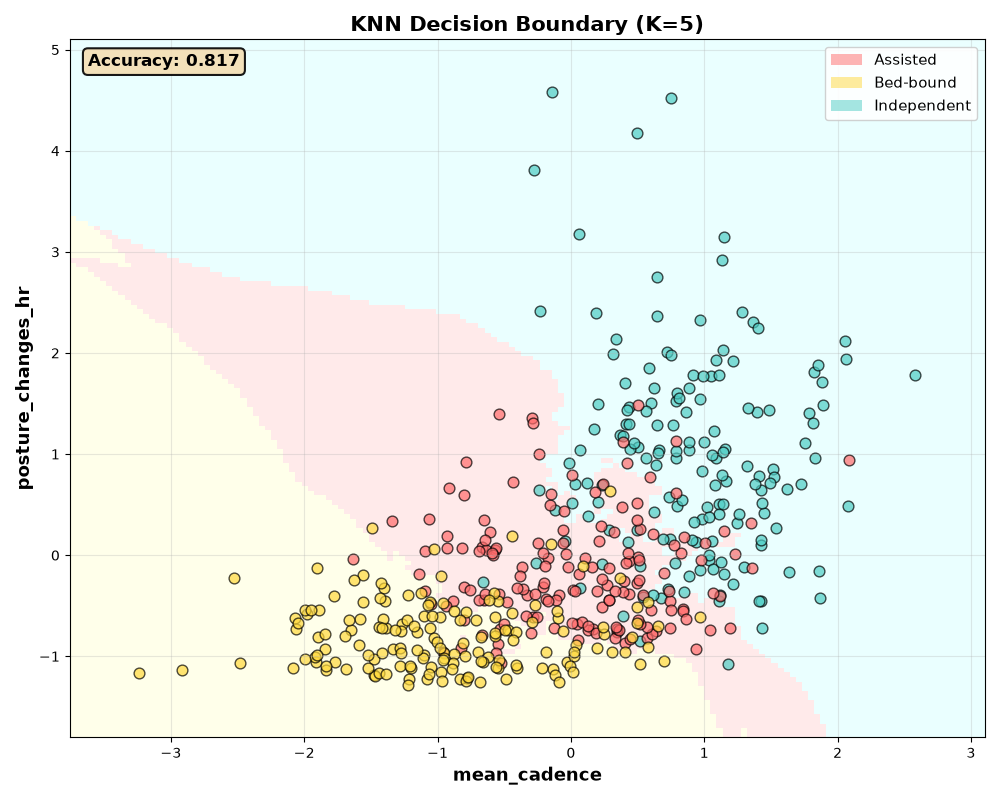

In [7]:
%matplotlib widget
import ipywidgets as widgets
from IPython.display import display

class InteractiveDecisionBoundary:
    """
    Interactive visualization of KNN decision boundaries with adjustable K.
    """
    def __init__(self, X_data, y_data, feature1='mean_cadence', feature2='posture_changes_hr'):
        self.X_data = X_data
        self.y_data = y_data
        self.feature1 = feature1
        self.feature2 = feature2
        
        # Get 2D data
        feature_indices = [X.columns.get_loc(feature1), X.columns.get_loc(feature2)]
        self.X_2d = X_data[:, feature_indices]
        
        # Color maps
        self.cmap_light = ListedColormap(['#CCFFFF', '#FFCCCC', '#FFFFCC'])
        self.colors = {'Independent': '#4ECDC4', 'Assisted': '#FF6B6B', 'Bed-bound': '#FFD93D'}
        
        # Create mesh grid (do this once for performance)
        x_min, x_max = self.X_2d[:, 0].min() - 0.5, self.X_2d[:, 0].max() + 0.5
        y_min, y_max = self.X_2d[:, 1].min() - 0.5, self.X_2d[:, 1].max() + 0.5
        self.xx, self.yy = np.meshgrid(np.linspace(x_min, x_max, 150),
                                        np.linspace(y_min, y_max, 150))
        
        # Create K slider
        self.k_slider = widgets.IntSlider(value=5, min=1, max=30, step=1,
                                          description='K neighbors:',
                                          style={'description_width': '100px'},
                                          layout=widgets.Layout(width='400px'),
                                          continuous_update=False)
        self.k_slider.observe(self.update_plot, names='value')
        
        self.status_label = widgets.HTML(value='')
        
        # Create figure
        self.fig, self.ax = plt.subplots(1, 1, figsize=(10, 8))
        self.fig.canvas.header_visible = False
        
        # Display widgets
        display(self.k_slider)
        display(self.status_label)
        
        # Initial plot
        self.update_plot(None)
        plt.tight_layout()
        plt.show()
    
    def update_plot(self, change):
        """Update the decision boundary for current K value."""
        k = self.k_slider.value
        
        self.ax.clear()
        
        # Train KNN
        knn_viz = KNeighborsClassifier(n_neighbors=k)
        knn_viz.fit(self.X_2d, self.y_data)
        
        # Predict for mesh
        Z = knn_viz.predict(np.c_[self.xx.ravel(), self.yy.ravel()])
        Z_numeric = np.array([['Independent', 'Assisted', 'Bed-bound'].index(z) for z in Z])
        Z_numeric = Z_numeric.reshape(self.xx.shape)
        
        # Plot decision boundary
        self.ax.pcolormesh(self.xx, self.yy, Z_numeric, cmap=self.cmap_light, 
                          alpha=0.4, shading='auto')
        
        # Plot training points
        for phenotype in ['Independent', 'Assisted', 'Bed-bound']:
            mask = self.y_data == phenotype
            self.ax.scatter(self.X_2d[mask, 0], self.X_2d[mask, 1],
                           c=self.colors[phenotype], label=phenotype,
                           edgecolors='black', s=60, alpha=0.7)
        
        self.ax.set_xlabel(self.feature1, fontsize=13, fontweight='bold')
        self.ax.set_ylabel(self.feature2, fontsize=13, fontweight='bold')
        self.ax.set_title(f'KNN Decision Boundary (K={k})', fontsize=15, fontweight='bold')
        handles, labels = ax.get_legend_handles_labels()
        order = [0, 2, 1]  # your custom order
        self.ax.legend([handles[i] for i in order], [labels[i] for i in order], fontsize=11, framealpha=0.9)
        self.ax.grid(True, alpha=0.3)
        
        # Calculate accuracy
        accuracy = knn_viz.score(self.X_2d, self.y_data)
        self.ax.text(0.02, 0.98, f'Accuracy: {accuracy:.3f}',
                    transform=self.ax.transAxes, fontsize=12, fontweight='bold',
                    verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.9,
                             edgecolor='black', linewidth=1.5))
        
        # Update status with interpretation
        if k == 1:
            msg = "⚠️ K=1: Very jagged boundaries (high variance, overfitting risk)"
        elif k <= 5:
            msg = "K={}: Captures local patterns, may be sensitive to noise".format(k)
        elif k <= 15:
            msg = "✅ K={}: Good balance between bias and variance".format(k)
        else:
            msg = "K={}: Smoother boundaries (higher bias, may underfit)".format(k)
        
        self.status_label.value = f'<b>{msg}</b>'
        
        self.fig.canvas.draw_idle()

# Launch interactive decision boundary
print("📊 Interactive KNN Decision Boundary")
print("=" * 50)
print("• Drag the K slider to see how decision boundaries change")
print("• Watch accuracy and boundary smoothness trade off")
print("=" * 50)

boundary_explorer = InteractiveDecisionBoundary(X_train_scaled, y_train)

## 6. Finding the Optimal K Value

The choice of K is crucial:
- **K too small**: Noisy predictions, overfitting
- **K too large**: Over-smoothing, underfitting

Let's systematically find the best K for our phenotype classification problem.

🔬 Testing K values from 1 to 50...



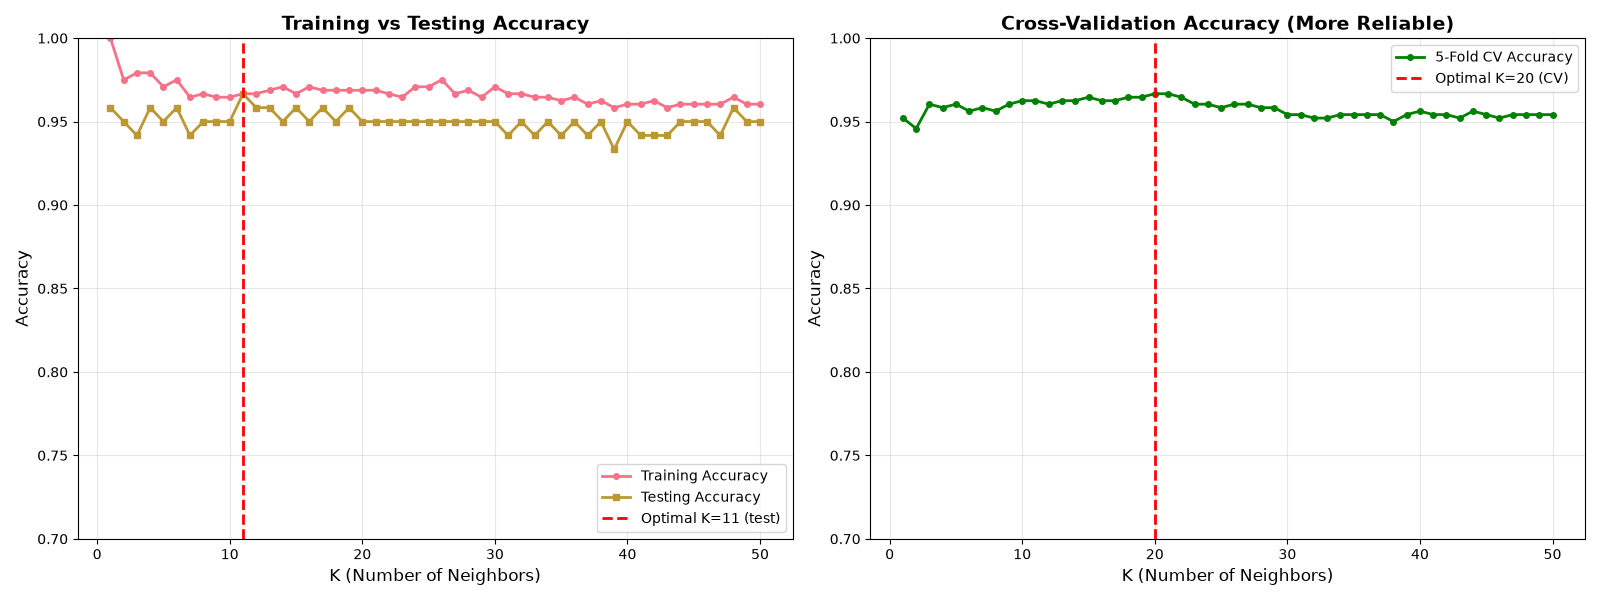


📊 K Selection Results:
Optimal K (test set):           11 (accuracy: 0.967)
Optimal K (cross-validation):   20 (accuracy: 0.967)

💡 Recommendations:
   • Use K=20 for robust performance
   • Typical rule of thumb: K = √(n_samples) = 21
   • Always use odd K for binary classification (avoids ties)

🎯 Final Model Performance (K=20):
   Test Accuracy: 0.950


In [8]:
# Test different K values
k_range = range(1, 51)
train_scores = []
test_scores = []
cv_scores = []

print("🔬 Testing K values from 1 to 50...\n")

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    
    # Train and evaluate
    knn.fit(X_train_scaled, y_train)
    train_scores.append(knn.score(X_train_scaled, y_train))
    test_scores.append(knn.score(X_test_scaled, y_test))
    
    # Cross-validation score (more reliable)
    cv_score = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(cv_score.mean())

# Find optimal K
optimal_k_test = k_range[np.argmax(test_scores)]
optimal_k_cv = k_range[np.argmax(cv_scores)]

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Training vs Testing Accuracy
ax1.plot(k_range, train_scores, label='Training Accuracy', linewidth=2, marker='o', markersize=4)
ax1.plot(k_range, test_scores, label='Testing Accuracy', linewidth=2, marker='s', markersize=4)
ax1.axvline(optimal_k_test, color='red', linestyle='--', linewidth=2, 
            label=f'Optimal K={optimal_k_test} (test)')
ax1.set_xlabel('K (Number of Neighbors)', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('Training vs Testing Accuracy', fontweight='bold', fontsize=14)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_ylim([0.7, 1.0])

# Plot 2: Cross-Validation Accuracy
ax2.plot(k_range, cv_scores, label='5-Fold CV Accuracy', linewidth=2, 
         marker='o', markersize=4, color='green')
ax2.axvline(optimal_k_cv, color='red', linestyle='--', linewidth=2,
            label=f'Optimal K={optimal_k_cv} (CV)')
ax2.set_xlabel('K (Number of Neighbors)', fontsize=12)
ax2.set_ylabel('Accuracy', fontsize=12)
ax2.set_title('Cross-Validation Accuracy (More Reliable)', fontweight='bold', fontsize=14)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_ylim([0.7, 1.0])

plt.tight_layout()
plt.show()

print(f"\n📊 K Selection Results:")
print("=" * 60)
print(f"Optimal K (test set):           {optimal_k_test} (accuracy: {max(test_scores):.3f})")
print(f"Optimal K (cross-validation):   {optimal_k_cv} (accuracy: {max(cv_scores):.3f})")
print(f"\n💡 Recommendations:")
print(f"   • Use K={optimal_k_cv} for robust performance")
print(f"   • Typical rule of thumb: K = √(n_samples) = {int(np.sqrt(len(X_train)))}")
print(f"   • Always use odd K for binary classification (avoids ties)")

# Train final model with optimal K
final_knn = KNeighborsClassifier(n_neighbors=optimal_k_cv)
final_knn.fit(X_train_scaled, y_train)
final_accuracy = final_knn.score(X_test_scaled, y_test)

print(f"\n🎯 Final Model Performance (K={optimal_k_cv}):")
print(f"   Test Accuracy: {final_accuracy:.3f}")

## 7. Distance Metrics: How KNN Measures Similarity

KNN's performance depends critically on how we measure "distance" between patients. Let's explore different distance metrics and their impact.

🧮 Comparing Distance Metrics for Patient Mobility Phenotyping

Euclidean            | Train: 0.969 | Test: 0.950 | CV: 0.967
Manhattan            | Train: 0.973 | Test: 0.950 | CV: 0.969
Chebyshev            | Train: 0.960 | Test: 0.942 | CV: 0.940
Minkowski (p=3)      | Train: 0.969 | Test: 0.950 | CV: 0.956


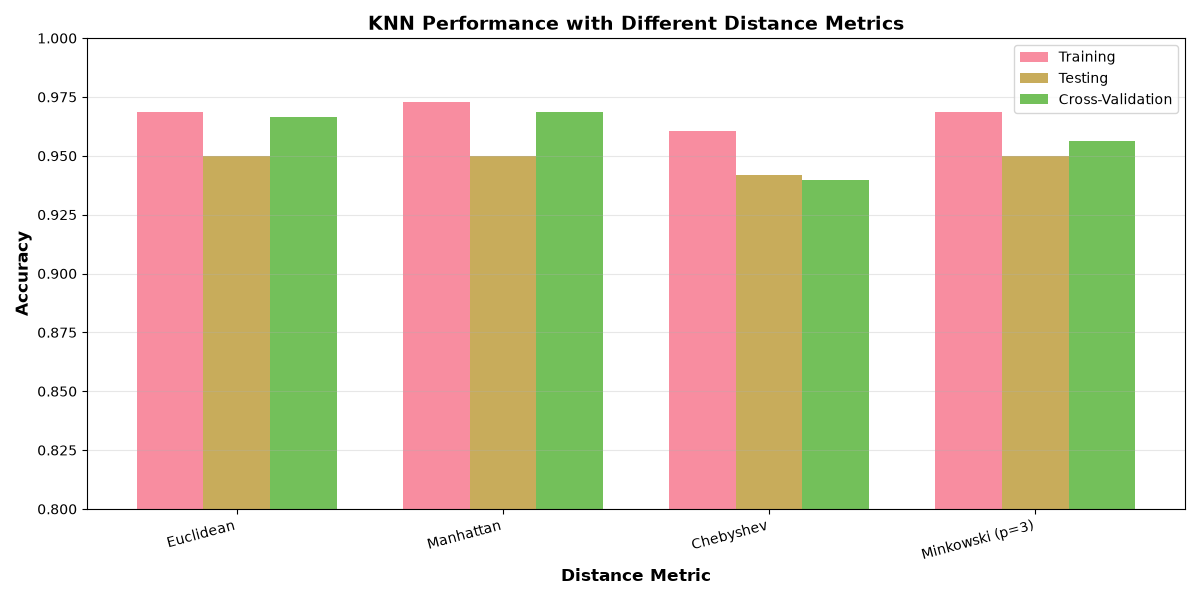


📐 Distance Metric Characteristics:
• Euclidean: Best for continuous features (standard choice)
• Manhattan: Less sensitive to outliers, good for grid-like patterns
• Chebyshev: Focuses on the single most different feature
• Minkowski: Generalizes Euclidean and Manhattan (p parameter)

💡 For mobility phenotypes: Euclidean works well with scaled features!


In [9]:
# Compare different distance metrics
distance_metrics = {
    'Euclidean': 'euclidean',      # Standard straight-line distance
    'Manhattan': 'manhattan',      # City-block distance (sum of absolute differences)
    'Chebyshev': 'chebyshev',      # Maximum difference in any dimension
    'Minkowski (p=3)': 'minkowski' # Generalized distance metric
}

results = []

print("🧮 Comparing Distance Metrics for Patient Mobility Phenotyping\n")
print("=" * 70)

for name, metric in distance_metrics.items():
    if metric == 'minkowski':
        knn = KNeighborsClassifier(n_neighbors=optimal_k_cv, metric=metric, p=3)
    else:
        knn = KNeighborsClassifier(n_neighbors=optimal_k_cv, metric=metric)
    
    # Train and evaluate
    knn.fit(X_train_scaled, y_train)
    train_acc = knn.score(X_train_scaled, y_train)
    test_acc = knn.score(X_test_scaled, y_test)
    cv_acc = cross_val_score(knn, X_train_scaled, y_train, cv=5).mean()
    
    results.append({
        'Metric': name,
        'Train Acc': train_acc,
        'Test Acc': test_acc,
        'CV Acc': cv_acc
    })
    
    print(f"{name:20} | Train: {train_acc:.3f} | Test: {test_acc:.3f} | CV: {cv_acc:.3f}")

results_df = pd.DataFrame(results)

# Visualize comparison
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(results_df))
width = 0.25

ax.bar(x - width, results_df['Train Acc'], width, label='Training', alpha=0.8)
ax.bar(x, results_df['Test Acc'], width, label='Testing', alpha=0.8)
ax.bar(x + width, results_df['CV Acc'], width, label='Cross-Validation', alpha=0.8)

ax.set_xlabel('Distance Metric', fontsize=12, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax.set_title('KNN Performance with Different Distance Metrics', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(results_df['Metric'], rotation=15, ha='right')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim([0.8, 1.0])

plt.tight_layout()
plt.show()

print("\n📐 Distance Metric Characteristics:")
print("=" * 70)
print("• Euclidean: Best for continuous features (standard choice)")
print("• Manhattan: Less sensitive to outliers, good for grid-like patterns")
print("• Chebyshev: Focuses on the single most different feature")
print("• Minkowski: Generalizes Euclidean and Manhattan (p parameter)")
print("\n💡 For mobility phenotypes: Euclidean works well with scaled features!")

## 8. Making Predictions: Real-World Example

Let's use our trained KNN model to classify unknown patients and understand why it makes each prediction.

In [10]:
def predict_and_explain(knn_model, scaler, patient_features, k=5):
    """
    Make a prediction and show the K nearest neighbors that influenced it.
    """
    # Scale the input
    patient_scaled = scaler.transform([patient_features])
    
    # Get prediction and probabilities
    prediction = knn_model.predict(patient_scaled)[0]
    probabilities = knn_model.predict_proba(patient_scaled)[0]
    
    # Get nearest neighbors
    distances, indices = knn_model.kneighbors(patient_scaled, n_neighbors=k)
    
    print("\n" + "=" * 70)
    print("🩺  MOBILITY PHENOTYPE REPORT")
    print("=" * 70)
    
    print("\n📊 Patient Movement Profile:")
    feature_names = ['Mean Cadence', 'Cadence Var', 'Posture Changes/hr',
                    'Out of Room %', 'Gait Radius (m)', 'Active Minutes']
    for name, value in zip(feature_names, patient_features):
        print(f"   {name:20}: {value:.2f}")
    
    print(f"\n🎯 Predicted Phenotype: {prediction}")
    print("\n📈 Confidence Scores:")
    for phenotype, prob in zip(knn_model.classes_, probabilities):
        bar = '█' * int(prob * 50)
        print(f"   {phenotype:10} {prob:5.1%} {bar}")
    
    print(f"\n🔍 {k} Nearest Neighbors (similar patients):")
    print(f"   {'Type':<10} {'Distance':<12} {'Features'}")
    print("   " + "-" * 65)
    
    for i, (dist, idx) in enumerate(zip(distances[0], indices[0])):
        neighbor_phenotype = y_train.iloc[idx]
        neighbor_features = X_train.iloc[idx].values
        feature_str = f"Cadence:{neighbor_features[0]:.1f}, Posture:{neighbor_features[2]:.1f}"
        print(f"   {neighbor_phenotype:<10} {dist:<12.3f} {feature_str}")
    
    print("\n💡 Why this prediction?")
    neighbor_types = [y_train.iloc[idx] for idx in indices[0]]
    from collections import Counter
    vote_counts = Counter(neighbor_types)
    print(f"   Vote breakdown: {dict(vote_counts)}")
    print(f"   Winner: {prediction} (most common among neighbors)")
    print("=" * 70)

# Test Case 1: Clearly an independent patient
print("\n🩺 TEST CASE 1: Suspected Independent Patient")
independent_patient = [112.0, 0.4, 13.0, 62.0, 70.0, 300.0]  # Brisk, steady, walks far
predict_and_explain(final_knn, scaler, independent_patient, k=optimal_k_cv)

# Test Case 2: Clearly a patient who needs assistance
print("\n\n🧑‍🦽 TEST CASE 2: Suspected Assisted Patient")
assisted_patient = [70.0, 2.6, 4.5, 16.0, 11.0, 80.0]  # Slow, irregular, short walks
predict_and_explain(final_knn, scaler, assisted_patient, k=optimal_k_cv)

# Test Case 3: A bed-bound patient
print("\n\n🛏️ TEST CASE 3: Suspected Bed-bound Patient")
bedbound_patient = [26.0, 2.2, 1.0, 2.0, 1.5, 14.0]  # Transfers only, confined to bed space
predict_and_explain(final_knn, scaler, bedbound_patient, k=optimal_k_cv)


🩺 TEST CASE 1: Suspected Independent Patient

🩺  MOBILITY PHENOTYPE REPORT

📊 Patient Movement Profile:
   Mean Cadence        : 112.00
   Cadence Var         : 0.40
   Posture Changes/hr  : 13.00
   Out of Room %       : 62.00
   Gait Radius (m)     : 70.00
   Active Minutes      : 300.00

🎯 Predicted Phenotype: Independent

📈 Confidence Scores:
   Assisted    0.0% 
   Bed-bound   0.0% 
   Independent 100.0% ██████████████████████████████████████████████████

🔍 20 Nearest Neighbors (similar patients):
   Type       Distance     Features
   -----------------------------------------------------------------
   Independent 0.962        Cadence:108.8, Posture:11.8
   Independent 1.129        Cadence:105.2, Posture:11.9
   Independent 1.134        Cadence:99.6, Posture:14.0
   Independent 1.169        Cadence:117.3, Posture:13.7
   Independent 1.247        Cadence:97.4, Posture:13.3
   Independent 1.362        Cadence:95.0, Posture:10.1
   Independent 1.423        Cadence:94.9, Posture:12.

## 9. The Curse of Dimensionality

KNN has a critical weakness: as the number of features (dimensions) increases, the notion of "nearest neighbor" breaks down. Let's demonstrate why this matters for clinical AI.

⚠️  THE CURSE OF DIMENSIONALITY
As we add more sensors/features, KNN becomes less effective!

Features: 2 | Accuracy: 0.792 | Avg NN Distance: 0.093
Features: 3 | Accuracy: 0.842 | Avg NN Distance: 0.237
Features: 4 | Accuracy: 0.900 | Avg NN Distance: 0.390
Features: 5 | Accuracy: 0.942 | Avg NN Distance: 0.526
Features: 6 | Accuracy: 0.950 | Avg NN Distance: 0.679


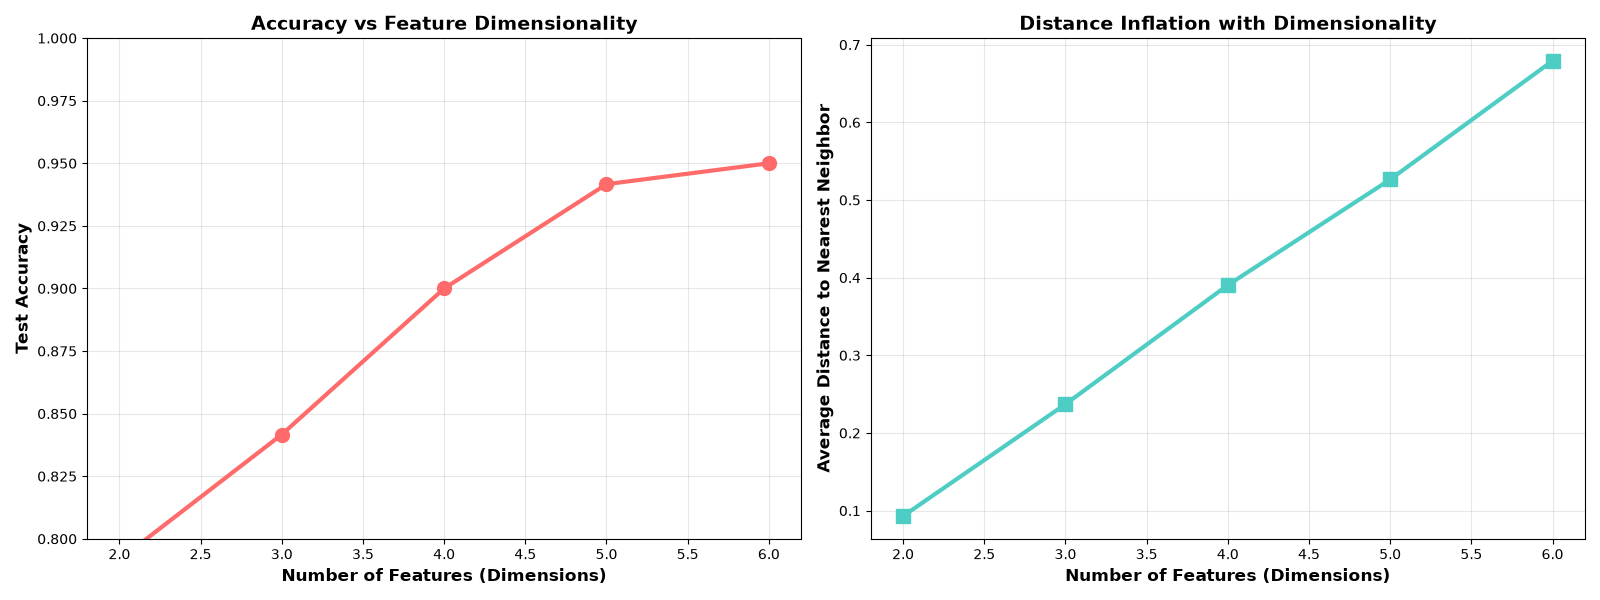


💡 Key Insights:
• As dimensions increase, distances between points become similar
• 'Nearest' neighbors are no longer meaningfully close
• In high dimensions, almost all points are far apart!
• This is why feature selection is crucial for KNN

🩺 Clinical Implications:
• Can't just throw every sensor channel at KNN
• Must select most relevant features (cadence, posture changes, etc.)
• Deep learning handles high dimensions better
• For 50+ channels, consider dimensionality reduction (PCA)


In [11]:
def demonstrate_curse_of_dimensionality():
    """
    Show how KNN performance degrades with increasing feature dimensions.
    A critical limitation for sensor-rich clinical applications.
    """
    print("⚠️  THE CURSE OF DIMENSIONALITY")
    print("=" * 70)
    print("As we add more sensors/features, KNN becomes less effective!\n")
    
    # Test with increasing number of features
    feature_counts = [2, 3, 4, 5, 6]
    accuracies = []
    nearest_distances = []
    
    for n_features in feature_counts:
        # Use first n features
        X_subset = X_train_scaled[:, :n_features]
        X_test_subset = X_test_scaled[:, :n_features]
        
        # Train KNN
        knn_temp = KNeighborsClassifier(n_neighbors=5)
        knn_temp.fit(X_subset, y_train)
        
        # Evaluate
        acc = knn_temp.score(X_test_subset, y_test)
        accuracies.append(acc)
        
        # Calculate average distance to nearest neighbor
        distances, _ = knn_temp.kneighbors(X_subset, n_neighbors=2)
        avg_dist = distances[:, 1].mean()  # Distance to 1st nearest neighbor
        nearest_distances.append(avg_dist)
        
        print(f"Features: {n_features} | Accuracy: {acc:.3f} | Avg NN Distance: {avg_dist:.3f}")
    
    # Visualize the curse
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Plot 1: Accuracy vs Dimensions
    ax1.plot(feature_counts, accuracies, marker='o', linewidth=3, markersize=10, color='#FF6B6B')
    ax1.set_xlabel('Number of Features (Dimensions)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Test Accuracy', fontsize=12, fontweight='bold')
    ax1.set_title('Accuracy vs Feature Dimensionality', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([0.8, 1.0])
    
    # Plot 2: Nearest Neighbor Distance vs Dimensions
    ax2.plot(feature_counts, nearest_distances, marker='s', linewidth=3, markersize=10, color='#4ECDC4')
    ax2.set_xlabel('Number of Features (Dimensions)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Average Distance to Nearest Neighbor', fontsize=12, fontweight='bold')
    ax2.set_title('Distance Inflation with Dimensionality', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print("\n💡 Key Insights:")
    print("=" * 70)
    print("• As dimensions increase, distances between points become similar")
    print("• 'Nearest' neighbors are no longer meaningfully close")
    print("• In high dimensions, almost all points are far apart!")
    print("• This is why feature selection is crucial for KNN")
    print("\n🩺 Clinical Implications:")
    print("• Can't just throw every sensor channel at KNN")
    print("• Must select most relevant features (cadence, posture changes, etc.)")
    print("• Deep learning handles high dimensions better")
    print("• For 50+ channels, consider dimensionality reduction (PCA)")

demonstrate_curse_of_dimensionality()

## 10. KNN vs Decision Trees: When to Use Each?

Let's compare KNN with decision trees (from Notebook 02a) to understand their trade-offs for clinical applications.

In [12]:
from sklearn.tree import DecisionTreeClassifier
import time

print("⚔️  KNN vs DECISION TREES: Head-to-Head Comparison")
print("=" * 70)

# Train decision tree for comparison
dt = DecisionTreeClassifier(max_depth=5, min_samples_split=20, random_state=42)
dt.fit(X_train, y_train)  # Note: DT doesn't need scaling!

# Compare performance
comparison = {
    'Metric': [],
    'KNN': [],
    'Decision Tree': []
}

# Accuracy
knn_acc = final_knn.score(X_test_scaled, y_test)
dt_acc = dt.score(X_test, y_test)
comparison['Metric'].append('Test Accuracy')
comparison['KNN'].append(f"{knn_acc:.3f}")
comparison['Decision Tree'].append(f"{dt_acc:.3f}")

# Training time
start = time.time()
final_knn.fit(X_train_scaled, y_train)
knn_train_time = time.time() - start

start = time.time()
dt.fit(X_train, y_train)
dt_train_time = time.time() - start

comparison['Metric'].append('Training Time (s)')
comparison['KNN'].append(f"{knn_train_time:.4f}")
comparison['Decision Tree'].append(f"{dt_train_time:.4f}")

# Prediction time
start = time.time()
_ = final_knn.predict(X_test_scaled)
knn_pred_time = time.time() - start

start = time.time()
_ = dt.predict(X_test)
dt_pred_time = time.time() - start

comparison['Metric'].append('Prediction Time (s)')
comparison['KNN'].append(f"{knn_pred_time:.4f}")
comparison['Decision Tree'].append(f"{dt_pred_time:.4f}")

# Display comparison table
comparison_df = pd.DataFrame(comparison)
print("\n" + comparison_df.to_string(index=False))

print("\n\n📊 DETAILED COMPARISON")
print("=" * 70)

print("\n🔵 K-NEAREST NEIGHBORS:")
print("   ✅ Strengths:")
print("      • Simple and intuitive (finds similar historical cases)")
print("      • No training time (just stores data)")
print("      • Naturally handles multi-class problems")
print("      • Can capture complex decision boundaries")
print("      • Works well with local patterns")
print("   ❌ Weaknesses:")
print("      • Slow predictions (must check all training data)")
print("      • Requires feature scaling")
print("      • Suffers from curse of dimensionality")
print("      • Memory intensive (stores all training data)")
print("      • Not interpretable (can't explain 'why')")

print("\n🟢 DECISION TREES:")
print("   ✅ Strengths:")
print("      • Highly interpretable (clear rules)")
print("      • Fast predictions (just follow tree branches)")
print("      • No feature scaling needed")
print("      • Handles mixed data types well")
print("      • Automatic feature selection")
print("   ❌ Weaknesses:")
print("      • Unstable (small data changes = different tree)")
print("      • Prone to overfitting")
print("      • Struggles with diagonal decision boundaries")
print("      • Can't capture smooth patterns")

print("\n\n🩺 CLINICAL USE CASE RECOMMENDATIONS:")
print("=" * 70)
print("\n📍 Use KNN when:")
print("   • You have clear examples of each mobility phenotype")
print("   • Real-time prediction speed is not critical")
print("   • Feature space is low-dimensional (< 10 features)")
print("   • Patterns are local and irregular")
print("   • Example: Mobility phenotype identification from wearable data")

print("\n📍 Use Decision Trees when:")
print("   • You need to explain decisions to regulators")
print("   • Real-time predictions are critical (autonomous systems)")
print("   • Features have clear thresholds (cadence > 100 steps/min)")
print("   • Working with mixed sensor types")
print("   • Example: Fall-risk screening rules")

print("\n📍 Use Ensemble Methods (Random Forest, XGBoost) when:")
print("   • You need maximum accuracy")
print("   • Production deployment with stable predictions")
print("   • Can afford some loss of interpretability")
print("   • Example: Readmission risk, discharge planning")

⚔️  KNN vs DECISION TREES: Head-to-Head Comparison

             Metric    KNN Decision Tree
      Test Accuracy  0.950         0.900
  Training Time (s) 0.0006        0.0015
Prediction Time (s) 0.0010        0.0003


📊 DETAILED COMPARISON

🔵 K-NEAREST NEIGHBORS:
   ✅ Strengths:
      • Simple and intuitive (finds similar historical cases)
      • No training time (just stores data)
      • Naturally handles multi-class problems
      • Can capture complex decision boundaries
      • Works well with local patterns
   ❌ Weaknesses:
      • Slow predictions (must check all training data)
      • Requires feature scaling
      • Suffers from curse of dimensionality
      • Memory intensive (stores all training data)
      • Not interpretable (can't explain 'why')

🟢 DECISION TREES:
   ✅ Strengths:
      • Highly interpretable (clear rules)
      • Fast predictions (just follow tree branches)
      • No feature scaling needed
      • Handles mixed data types well
      • Automatic feature 

## 11. Confusion Matrix Analysis

Let's examine where KNN makes mistakes and understand the confusion between phenotypes.

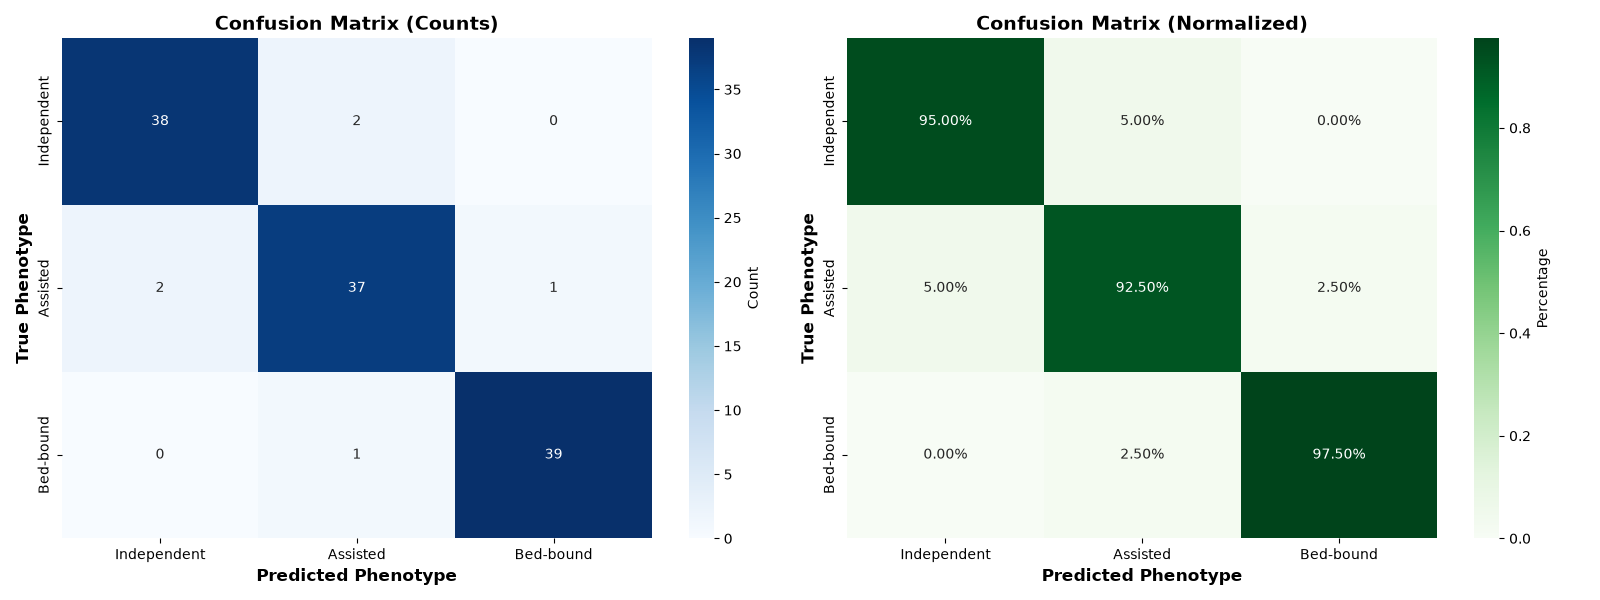


🔍 Confusion Matrix Insights:
Diagonal: Correct predictions
Off-diagonal: Misclassifications

Independent patients: 95.0% correctly classified
         → 2 confused with Assisted
Assisted patients: 92.5% correctly classified
         → 2 confused with Independent
         → 1 confused with Bed-bound
Bed-bound patients: 97.5% correctly classified
         → 1 confused with Assisted

💡 Clinical Safety Implications:
   • High accuracy on all phenotypes shows KNN works well
   • Misclassifications typically involve patients mid-rehabilitation
   • For care decisions, combine with a clinician's assessment
   • Consider ensemble methods for production systems


In [13]:
# Generate predictions
y_pred_final = final_knn.predict(X_test_scaled)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_final, labels=['Independent', 'Assisted', 'Bed-bound'])
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Absolute counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1,
           xticklabels=['Independent', 'Assisted', 'Bed-bound'],
           yticklabels=['Independent', 'Assisted', 'Bed-bound'],
           cbar_kws={'label': 'Count'})
ax1.set_xlabel('Predicted Phenotype', fontsize=12, fontweight='bold')
ax1.set_ylabel('True Phenotype', fontsize=12, fontweight='bold')
ax1.set_title('Confusion Matrix (Counts)', fontsize=14, fontweight='bold')

# Normalized percentages
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Greens', ax=ax2,
           xticklabels=['Independent', 'Assisted', 'Bed-bound'],
           yticklabels=['Independent', 'Assisted', 'Bed-bound'],
           cbar_kws={'label': 'Percentage'})
ax2.set_xlabel('Predicted Phenotype', fontsize=12, fontweight='bold')
ax2.set_ylabel('True Phenotype', fontsize=12, fontweight='bold')
ax2.set_title('Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n🔍 Confusion Matrix Insights:")
print("=" * 70)
print("Diagonal: Correct predictions")
print("Off-diagonal: Misclassifications\n")

# Analyze misclassifications
for i, true_type in enumerate(['Independent', 'Assisted', 'Bed-bound']):
    correct = cm[i, i]
    total = cm[i].sum()
    accuracy = correct / total if total > 0 else 0
    print(f"{true_type:8} patients: {accuracy:5.1%} correctly classified")
    
    # Show main confusion
    for j, pred_type in enumerate(['Independent', 'Assisted', 'Bed-bound']):
        if i != j and cm[i, j] > 0:
            print(f"         → {cm[i,j]} confused with {pred_type}")

print("\n💡 Clinical Safety Implications:")
print("   • High accuracy on all phenotypes shows KNN works well")
print("   • Misclassifications typically involve patients mid-rehabilitation")
print("   • For care decisions, combine with a clinician's assessment")
print("   • Consider ensemble methods for production systems")

## 12. Summary: KNN for Clinical AI

### ✅ What We've Learned

**K-Nearest Neighbors Algorithm:**
- **Core concept**: Classify by finding similar historical cases
- **Simple intuition**: "Show me patients like this one - what was true of them?"
- **Three key parameters**: K (neighbors), distance metric, feature scaling

**Strengths for Clinical Applications:**
- ✅ Intuitive and easy to explain to clinicians - it is case-based reasoning
- ✅ No training phase (instant model updates with new data)
- ✅ Naturally handles multi-class problems (many phenotypes)
- ✅ Works well with local, irregular patterns
- ✅ Good for behaviour- and phenotype-based classification

**Limitations to Consider:**
- ❌ Slow predictions (must scan all training data)
- ❌ Curse of dimensionality (struggles with many sensor channels)
- ❌ Requires careful feature scaling
- ❌ Memory intensive (stores all training examples, including patient records)
- ❌ Limited interpretability (can't extract rules)

### 🩺 Clinical Use Cases

**Excellent for:**
- Mobility phenotype classification (independent vs assisted vs bed-bound)
- Anomaly detection (find patients unlike any historical case)
- Similar-patient retrieval for case review
- Recovery-trajectory matching after surgery
- Small to medium datasets with clear patterns

**Not recommended for:**
- Real-time bedside alarms (too slow at scale)
- High-dimensional sensor fusion (50+ channels)
- Regulatory submissions that need interpretable rules
- Health-system-wide deployment (memory and privacy constraints - the model *is* the patient data)

### 🎯 Best Practices

1. **Always scale features** before using KNN
2. **Use cross-validation** to find optimal K
3. **Start with K = √n** as rule of thumb
4. **Use odd K** for binary classification (avoids ties)
5. **Select relevant features** (curse of dimensionality)
6. **Consider weighted KNN** (closer neighbors count more)
7. **Test different distance metrics** for your data
8. **Mind the privacy surface**: KNN stores every training record, so a deployed model carries identifiable data with it

### 📚 Next Steps

Now that you understand both decision trees and KNN:
- **Combine them**: Random Forests (Notebook 02b)
- **Sequential learning**: Gradient Boosting (Notebook 02c)
- **Production-grade**: XGBoost (Notebook 03)
- **Advanced similarity**: Support Vector Machines
- **Deep learning**: Neural networks for complex patterns

---

*This notebook is part of the CAIR AI Workshop series for healthcare professionals. You now have the foundation to apply similarity-based learning to patient phenotype analysis!*


## 🎓 Exercise: Try It Yourself!

**Challenge 1**: Modify the mobility phenotype generator to add a 4th class ("Rehab-progressing" patients whose cadence improves day by day). What K value works best?

**Challenge 2**: Try using only 2 features (mean cadence and posture changes). Does KNN perform better or worse? Why?

**Challenge 3**: Implement a weighted KNN where closer neighbors have more influence. Compare with standard KNN.

**Challenge 4**: Create a hybrid system that uses decision trees for fast initial screening and KNN for detailed classification.
